# EP5 y EP6 — Implementación de factores de costo médico

**Vicente Gabriel Zepeda Rojas** · SCY1102 Gestión de Proyectos de Datos  
Docente: Jorge Alberto Moscoso Santander

Continuidad del plan EP4: regresión lineal sobre log(costo), comparación M1/M2 mediante AIC y validación cruzada de cinco particiones, cuantificación de asociaciones y presupuesto **por grupos**. El alcance excluye causalidad, precisión individual y ejecución del piloto preventivo.

Este notebook muestra una ejecución verificable de la sesión de preparación. No reconstruye ni acredita seguimientos de semanas anteriores. La base pública de referencia no constituye una cartera real. El horizonte anual proviene del plan y no se puede verificar en el CSV.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import display, Image

# Ejecutar desde notebooks/ o desde la raíz del repositorio.
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.analysis import run

# Código único: vuelve a generar todos los resultados con semilla 42.
metrics = run(ROOT / "data/raw/insurance.csv", ROOT)
print("Ejecución:", metrics["executed_at_santiago"])
print("Modelo seleccionado:", metrics["selected_model"])

Ejecución: 2026-11-11T22:09:22.954936-03:00
Modelo seleccionado: M2_interaccion


## 1. Comprensión y preparación de datos — E2

Se conserva la base de 1.338 filas, cero nulos y una copia exacta adicional. Esa copia permanece en el mismo grupo de partición para impedir fuga entre conjuntos. No se descartan observaciones extremas sin una causa verificable.

In [2]:
quality = json.loads((ROOT / "results/data_quality.json").read_text(encoding="utf-8"))
display(pd.DataFrame([{k: quality[k] for k in ["rows_raw", "rows_validated", "missing_values", "duplicate_excess_rows", "duplicate_group_overlap_train_holdout"]}]))
print("SHA-256 de entrada:", quality["sha256_input"])
data = pd.read_csv(ROOT / "data/processed/insurance_validated.csv")
display(data[["age", "bmi", "children", "charges"]].describe().round(2))

,rows_raw,rows_validated,missing_values,duplicate_excess_rows,duplicate_group_overlap_train_holdout
0,1338,1338,0,1,0


SHA-256 de entrada: 388eff679557d08ac19f463d025de5e0b4adc482537c8456d19934d78621fd47


,age,bmi,children,charges
count,1338.00,1338.00,1338.00,1338.00
mean,39.21,30.66,1.09,13270.42
std,14.05,6.10,1.21,12110.01
min,18.00,15.96,0.00,1121.87
25%,27.00,26.30,0.00,4740.29
50%,39.00,30.40,1.00,9382.03
75%,51.00,34.69,2.00,16639.91
max,64.00,53.13,5.00,63770.43


,valor
n,1.338000e+03
mean_cost_usd,1.327042e+04
median_cost_usd,9.382033e+03
total_cost_usd,1.775582e+07
smokers_n,2.740000e+02
smokers_share,2.047833e-01
smokers_cost_share,4.945849e-01
top_10pct_n,1.340000e+02
top_10pct_cost_share,3.198243e-01
cost_over_20000_share,2.040359e-01


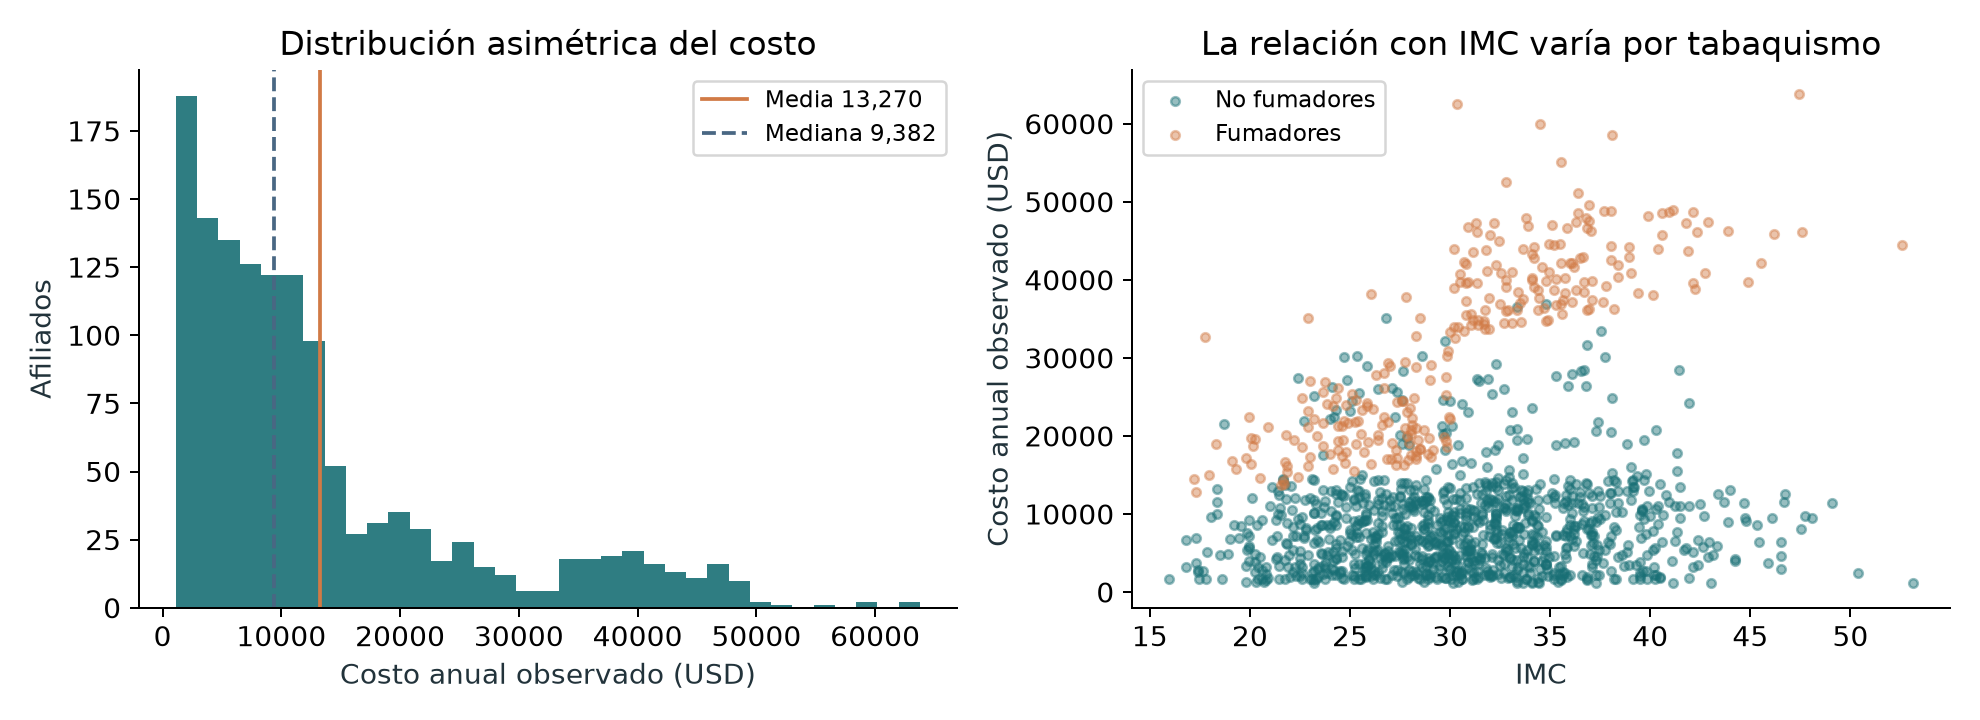

In [3]:
display(pd.DataFrame([metrics["summary"]]).T.rename(columns={0: "valor"}))
display(Image(filename=str(ROOT / "results/figures/01_eda_costos.png")))

## 2. Modelado y selección sin acceso al holdout — E3

M1 usa edad, sexo, IMC, hijos, tabaquismo y región. M2 añade tabaquismo × IMC. Se centra IMC en 30 para interpretar el contraste de fumadores. El split agrupa filas idénticas: 80% aproximado para entrenamiento y 20% reservado. Dentro de entrenamiento, `StratifiedGroupKFold` genera cinco particiones con semilla 42 y estratificación por tabaquismo.

La regla de selección es el menor MAE en USD de las predicciones fuera de fold (OOF), con AIC en escala log como evidencia complementaria. Se reportan RMSE y R² para exponer las diferencias entre criterios. La media de entrenamiento actúa como referencia simple. La retransformación usa factores de smearing de Duan por tabaquismo, calculados exclusivamente dentro de cada fold de entrenamiento.

,model,aic_train_log,cv_mae_usd,cv_rmse_usd,cv_r2_usd,cv_bias_usd,cv_r2_log
0,Baseline_media,NaN,9208.7122,12265.5989,-0.0014,-0.0877,-0.0029
1,M1_aditivo,1321.6085,5099.1488,9252.1761,0.4302,1341.9000,0.7587
2,M2_interaccion,1257.8819,5039.5183,9757.5602,0.3663,1502.1230,0.7726


,model,fold,n_train,n_validation,mae_usd,rmse_usd,r2_usd,bias_usd,r2_log
0,Baseline_media,1,855,214,8625.459,11301.686,-0.001,424.052,-0.001
1,Baseline_media,2,855,214,9495.024,12347.082,-0.006,941.564,-0.012
2,Baseline_media,3,856,213,9452.222,12568.202,-0.001,376.424,-0.007
3,Baseline_media,4,855,214,9257.106,12313.358,-0.009,-1138.700,-0.020
4,Baseline_media,5,855,214,9214.888,12747.653,-0.002,-602.019,-0.001
5,M1_aditivo,1,855,214,4886.801,8797.902,0.393,1934.878,0.791
6,M1_aditivo,2,855,214,5149.624,9765.666,0.371,2488.355,0.812
7,M1_aditivo,3,856,213,4948.046,8897.997,0.498,1651.960,0.777
8,M1_aditivo,4,855,214,5203.824,9090.997,0.450,406.505,0.727
9,M1_aditivo,5,855,214,5306.742,9663.947,0.424,229.252,0.683


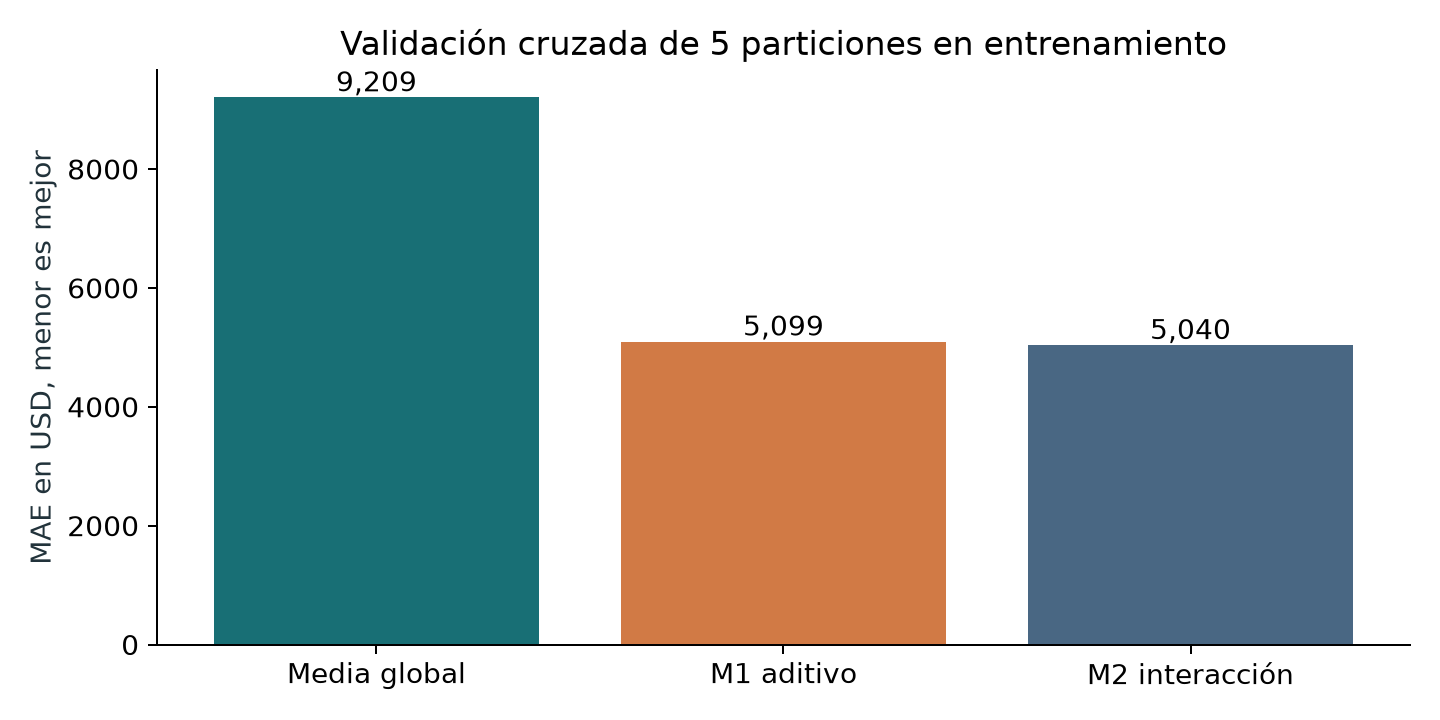

In [4]:
comparison = pd.read_csv(ROOT / "results/model_comparison.csv")
display(comparison.round(4))
display(pd.read_csv(ROOT / "results/cv_folds.csv").round(3))
display(Image(filename=str(ROOT / "results/figures/04_comparacion_modelos.png")))

## 3. Validación final y desviación del KPI

El holdout sólo evalúa el modelo previamente seleccionado. No se utiliza para elegir fórmula ni recalibrar el smearing. El modelo persistido tampoco incorpora esas observaciones. El KPI del plan fija MAE de referencia de USD 4.824, pero el plan no entrega particiones ni código de ese cálculo. Se compara con cautela y se declara el desvío real, sin atribuirle mejora si no cumple.

In [5]:
display(pd.DataFrame([metrics["holdout_selected"], metrics["holdout_baseline"]], index=["M2 seleccionado", "Media de entrenamiento"]).round(4))
cv_mae = comparison.loc[comparison.model == metrics["selected_model"], "cv_mae_usd"].iloc[0]
reference = metrics["planned_mae_reference_usd"]
print(f"MAE CV: USD {cv_mae:,.2f}; referencia EP4: USD {reference:,.0f}")
print(f"Desviación: USD {cv_mae-reference:,.2f} ({(cv_mae/reference-1)*100:.2f}%)")
print("Cumple referencia:", metrics["cv_mae_meets_reference"])
display(pd.read_csv(ROOT / "results/holdout_group_validation.csv").round(4))

,mae_usd,rmse_usd,r2_usd,bias_usd,r2_log
M2 seleccionado,4505.9533,8414.6712,0.4616,1198.5387,0.8063
Media de entrenamiento,8904.1858,11486.6153,-0.0032,650.8628,NaN


MAE CV: USD 5,039.52; referencia EP4: USD 4,824
Desviación: USD 215.52 (4.47%)
Cumple referencia: False


,smoker,n,charges_sum,charges_mean,charges_median,charges_std,expected_sum,expected_mean,se_mean,ci95_low,ci95_high,small_group,relative_budget_error
0,no,212,1.722634e+06,8125.6333,7353.1588,5972.5149,1.785287e+06,8421.1635,410.1940,7321.6530,8929.6135,False,0.0364
1,yes,57,1.707227e+06,29951.3482,29141.3603,10734.5164,1.966981e+06,34508.4448,1421.8214,27164.5782,32738.1182,False,0.1521


## 4. Asociaciones e incertidumbre

Los coeficientes se expresan mediante `100 × (exp(beta) − 1)` y errores estándar robustos HC3. Representan cambios de **media geométrica condicional** de costo, manteniendo las demás variables constantes. No equivalen a cambios de la media aritmética en USD ni a un efecto de intervenir sobre la persona. Con interacción, el contraste de fumadores depende del IMC.

Los p-valores son exploratorios: no corrigen pruebas múltiples, no resuelven variables omitidas ni validan causalidad. Los intervalos de grupos de `group_costs.csv` describen incertidumbre aproximada de la media observada y no son intervalos de predicción del modelo.

In [6]:
display(pd.read_csv(ROOT / "results/effects.csv").round(5))
display(pd.read_csv(ROOT / "results/coefficients.csv").round(5))

,comparison,log_effect,robust_se_hc3,percent_change,ci95_percent_low,ci95_percent_high,p_value_hc3
0,Edad: +1 año,0.03410,0.00112,3.46917,3.24319,3.69564,0.00000
1,Hijos: +1,0.09750,0.00978,10.24095,8.14830,12.37410,0.00000
2,Sexo: male frente a female,-0.07147,0.02691,-6.89763,-11.68069,-1.85553,0.00791
3,IMC: +1 en no fumadores,0.00465,0.00251,0.46561,-0.02777,0.96142,0.06440
4,IMC: +1 en fumadores,0.04695,0.00413,4.80678,3.96128,5.65916,0.00000
5,Fumador frente a no fumador con IMC 20,1.08385,0.05757,195.60385,164.06397,230.91087,0.00000
6,Fumador frente a no fumador con IMC 25,1.29537,0.04065,265.23301,237.25964,295.52658,0.00000
7,Fumador frente a no fumador con IMC 30,1.50688,0.03321,351.26324,322.82638,381.61260,0.00000
8,Fumador frente a no fumador con IMC 35,1.71840,0.04079,457.55779,414.71556,503.96599,0.00000
9,Fumador frente a no fumador con IMC 40,1.92991,0.05776,588.88990,515.15379,671.46448,0.00000


,term,coefficient_log,robust_se_hc3,p_value_hc3,ci95_log_low,ci95_log_high
0,Intercept,7.46228,0.06076,0.00000,7.34320,7.58136
1,C(sex)[T.male],-0.07147,0.02691,0.00791,-0.12421,-0.01873
2,C(smoker)[T.yes],1.50688,0.03321,0.00000,1.44179,1.57197
3,C(region)[T.northwest],-0.04366,0.03811,0.25195,-0.11836,0.03104
4,C(region)[T.southeast],-0.13659,0.03993,0.00062,-0.21485,-0.05833
5,C(region)[T.southwest],-0.14648,0.03682,0.00007,-0.21865,-0.07431
6,age,0.03410,0.00112,0.00000,0.03192,0.03629
7,bmi_c,0.00465,0.00251,0.06440,-0.00028,0.00957
8,bmi_c:C(smoker)[T.yes],0.04230,0.00471,0.00000,0.03306,0.05154
9,children,0.09750,0.00978,0.00000,0.07833,0.11666


## 5. Revisión de residuos y respuesta al desvío

Se aplican Breusch–Pagan, Jarque–Bera e influencia de Cook. El incumplimiento de homocedasticidad o normalidad se informa como limitación. HC3 mejora la inferencia asintótica frente a heterocedasticidad, pero no elimina el sesgo de especificación. El smearing por tabaquismo tampoco garantiza calibración de medias en todos los subgrupos.

La acción correctiva propuesta es validar una recalibración de medias y una especificación no lineal con un nuevo protocolo de validación; no se tunea con este holdout. Antes de presupuestar con una cartera real se necesitan validación externa, más variables y aprobación del patrocinador.

{
  "sample": "entrenamiento",
  "n": 1069,
  "breusch_pagan": {
    "lm": 65.64554227510344,
    "p_value": 1.0803064479063167e-10
  },
  "jarque_bera": {
    "statistic": 1649.9202798765234,
    "p_value": 0.0
  },
  "p_value_note": "Un p-valor calculado como 0.0 indica subdesbordamiento numérico, no probabilidad exactamente cero.",
  "condition_number": 197.874130515967,
  "max_cooks_distance": 0.021156067455540117,
  "n_cooks_above_4_over_n": 73,
  "interpretation": "Revisar p-valores y gráficos. Se utilizan errores estándar HC3. La normalidad/varianza constante pueden fallar. La independencia entre afiliados no puede verificarse sin identificadores. Asociación observacional, sin causalidad."
}


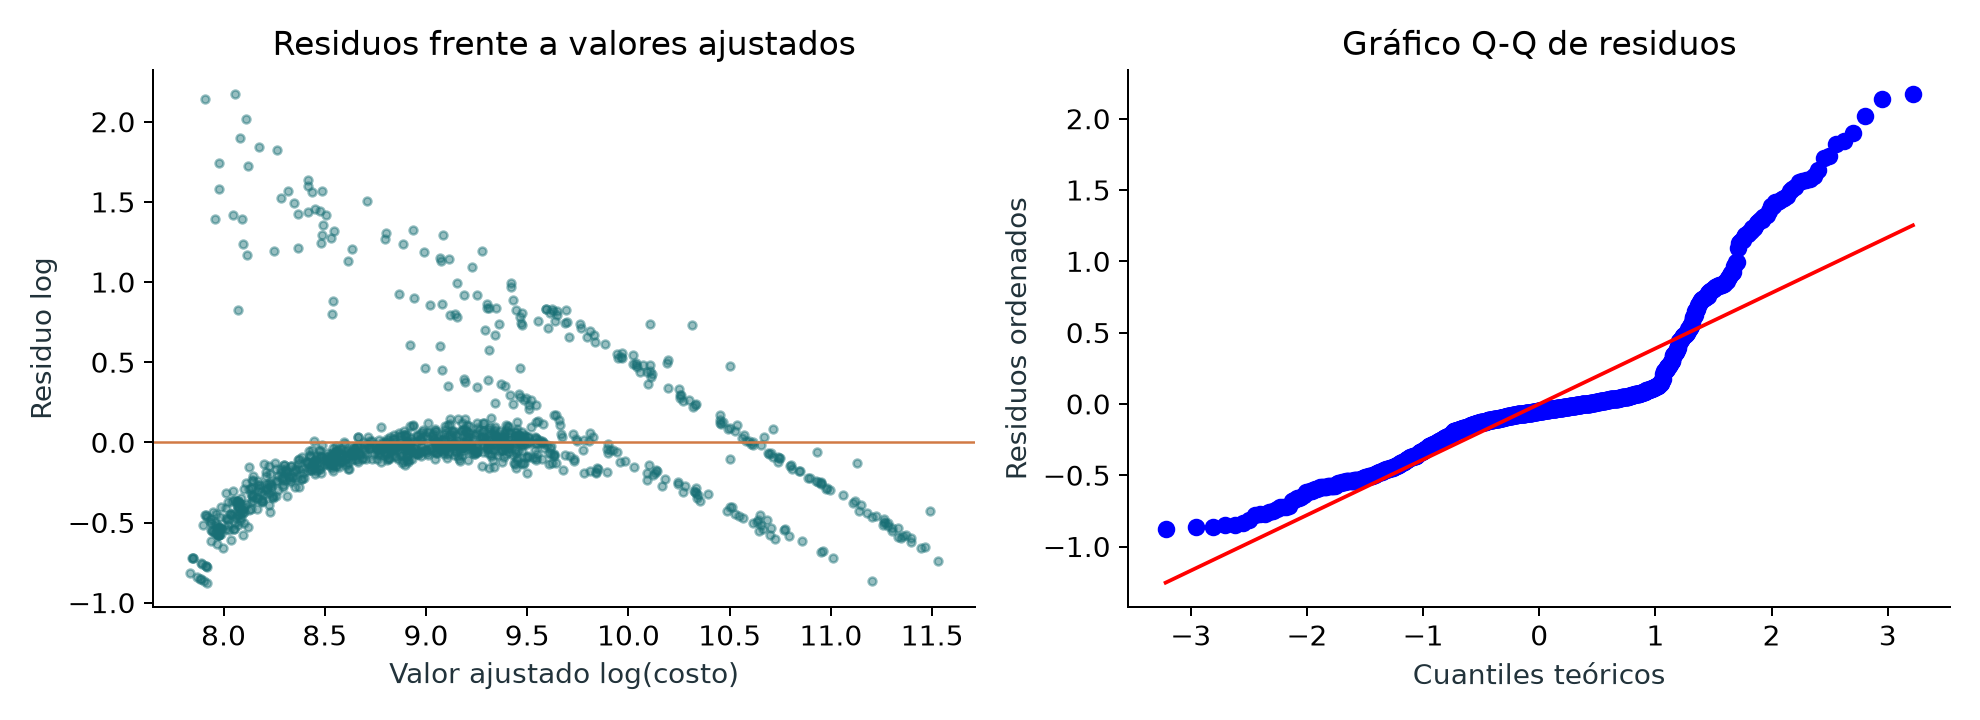

In [7]:
diagnostics = json.loads((ROOT / "results/residual_diagnostics.json").read_text(encoding="utf-8"))
print(json.dumps(diagnostics, indent=2, ensure_ascii=False))
display(Image(filename=str(ROOT / "results/figures/02_diagnosticos.png")))

## 6. Entregable funcional agregado — RF3 y RF4

Se publican medias observadas y estimadas por grupo, con tamaño de muestra. Las medias ajustadas sobre el conjunto de referencia son resultados descriptivos, no una nueva medición de exactitud externa. La CLI y el dashboard ocultan celdas de menos de cinco observaciones y marcan las de menos de veinte.

,smoker,bmi_group,n,charges_mean,expected_mean,small_group
2,no,IMC < 30,502,7977.03,7959.22,False
3,no,IMC >= 30,562,8842.69,9094.40,False
4,yes,IMC < 30,129,21363.22,28591.23,False
5,yes,IMC >= 30,145,41557.99,47358.63,False


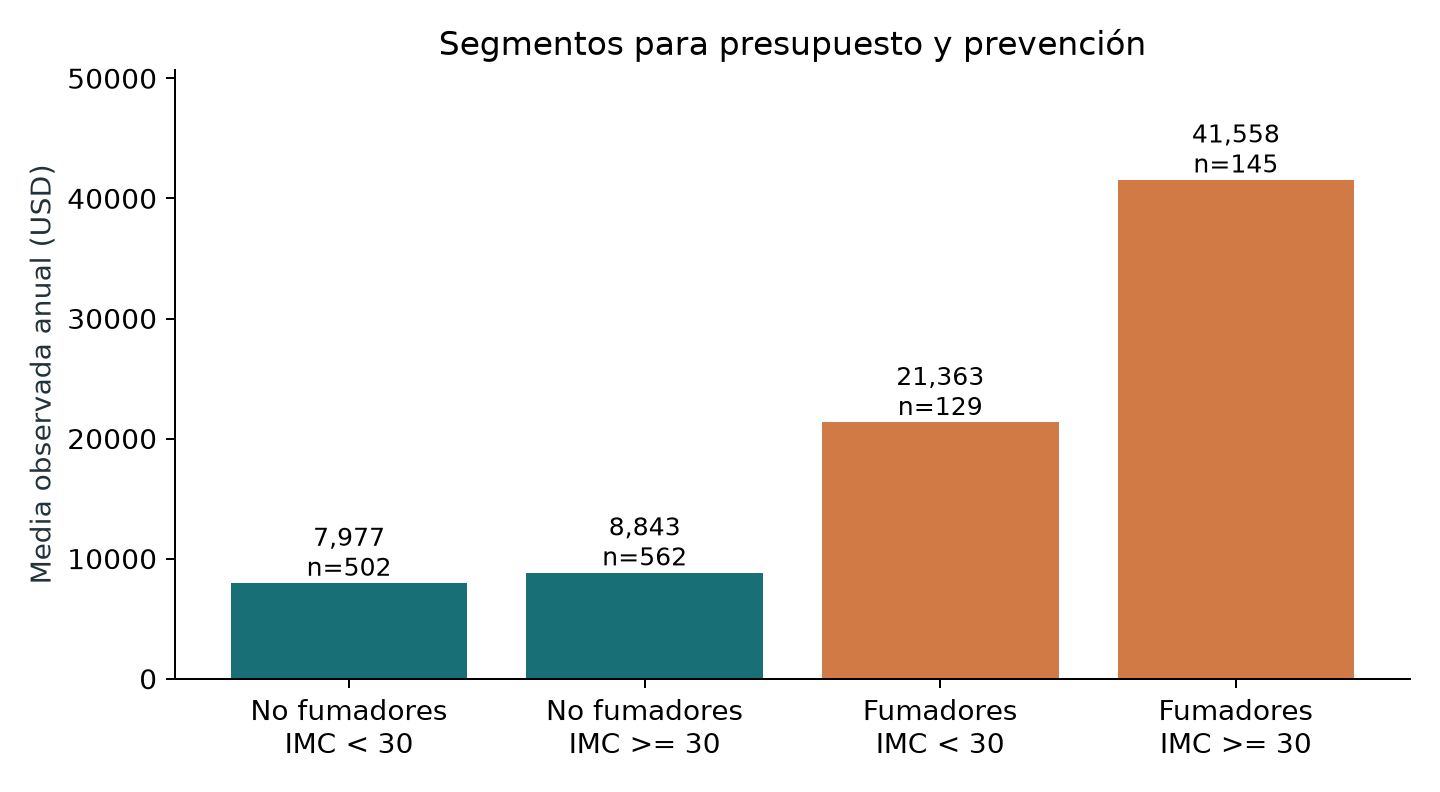

Demostración en terminal: python -m src.cli --group smoker,bmi_group --output results/cli_example.csv


In [8]:
from src.cli import report
display(report("smoker,bmi_group").round(2))
display(Image(filename=str(ROOT / "results/figures/03_costos_grupo.png")))
print("Demostración en terminal: python -m src.cli --group smoker,bmi_group --output results/cli_example.csv")

## 7. Reproducibilidad y archivos verificables

- `src/analysis.py`: validación, particiones, M1/M2, AIC, CV, holdout, diagnósticos y agregados.
- `results/split_manifest.csv`: fila, grupo de duplicado, conjunto y fold de validación.
- `results/cv_predictions.csv`: predicciones OOF, permiten recomputar el MAE independientemente.
- `models/factors_model.joblib`: modelo seleccionado entrenado sin holdout, para auditoría local. Sólo cargar artefactos de confianza.
- `results/metrics.json`, `results/data_quality.json` y `results/logs/execution.json`: métricas, integridad y registro de esta sesión.
- `tests/test_analysis.py`: pruebas de ausencia de fuga, rechazo de entradas inválidas, conciliación de agregados y coherencia de métricas.

Para repetir: crear un entorno Python 3.12, instalar `requirements.txt`, ejecutar `python -m src.analysis`, `python -m pytest -q` y abrir este notebook. El tablero de gestión y el informe distinguen resultados técnicos completados de aprobaciones y piloto pendientes.

In [9]:
print("Versiones ejecutadas:")
display(pd.DataFrame(metrics["versions"].items(), columns=["paquete", "versión"]))
manifest = pd.read_csv(ROOT / "results/split_manifest.csv")
train_groups = set(manifest.loc[manifest.split == "train", "duplicate_group"])
test_groups = set(manifest.loc[manifest.split == "holdout", "duplicate_group"])
assert not train_groups & test_groups
assert len(data) == 1338 and quality["missing_values"] == 0
print("Control final: base conservada y cero grupos duplicados compartidos entre train y holdout.")

Versiones ejecutadas:


,paquete,versión
0,pandas,3.0.1
1,numpy,2.5.4
2,scipy,1.18.1
3,scikit-learn,1.9.1
4,statsmodels,0.15.0
5,matplotlib,3.11.2
6,joblib,1.6.0


Control final: base conservada y cero grupos duplicados compartidos entre train y holdout.
